# 🏠 Real Estate Valuation & Property Price Prediction
## Production Regression Pipeline with SQL, Scikit-Learn, and XGBoost

### Project Overview
Accurate property valuation requires capturing non-linear interactions between structural home features (such as living square footage, bathroom count, and construction era) and localized macroeconomic indicators (such as school quality ratings and neighborhood crime indices).

This project implements an end-to-end Machine Learning regression pipeline:
1. **Relational Data Extraction (SQL):** Ingest and merge distributed property records and neighborhood telemetry from SQLite into a consolidated analytical dataset.
2. **Missing Data Diagnosis & Imputation:** Handle missing values across continuous features (e.g. square footage, bedrooms) and categorical indicators (garage status) using leak-free imputation strategies.
3. **Scikit-Learn Preprocessing Architecture:** Construct a dual-stream `ColumnTransformer` with median imputation and standard scaling for numeric features, alongside most-frequent imputation and one-hot encoding for categorical variables.
4. **Baseline Modeling (`XGBRegressor`):** Train an initial gradient boosted regression tree model on the transformed feature space and benchmark performance using MAE, RMSE, $R^2$, and MAPE.
5. **Hyperparameter Optimization (`RandomizedSearchCV`):** Run 5-fold cross-validated tuning over tree depth, learning rate, estimator count, and feature subsampling ratios to minimize prediction loss.
6. **Residual Diagnostics & Model Explainability:** Evaluate prediction fidelity via actual-versus-predicted plots, residual error distribution curves, and global feature importance attributions.
7. **Production Deployment Packaging:** Encapsulate preprocessing transformations and the optimized estimator into a unified Scikit-Learn `Pipeline` ready for zero-friction inference on raw inputs.

---
## 1. Environment Configuration & Library Imports

We import standard data manipulation, visualization, pipeline construction, and machine learning libraries.

In [1]:
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print("Environment configured successfully.")

Environment configured successfully.


---
## 2. Relational Database Extraction (SQL)

Property data is split across two relational tables inside `real_estate.db`:
- `houses`: Contains individual listing records, physical attributes (`sqft`, `bedrooms`, `bathrooms`, `year_built`), garage presence, foreign key `neighborhood_id`, and closing sale `price`.
- `neighborhoods`: Contains neighborhood lookup metadata, including name, `school_rating` (1 to 10 scale), and `crime_rate_index`.

We execute a relational `JOIN` on `neighborhood_id`, explicitly selecting and aliasing columns to eliminate redundant key duplication.

In [2]:
# Connect to SQLite database
conn = sqlite3.connect('real_estate.db')

# Extract and join housing and neighborhood data
query = """
SELECT 
    h.house_id,
    h.sqft,
    h.bedrooms,
    h.bathrooms,
    h.year_built,
    h.has_garage,
    n.neighborhood_name,
    n.school_rating,
    n.crime_rate_index,
    h.price
FROM houses h
JOIN neighborhoods n ON h.neighborhood_id = n.neighborhood_id
"""

df = pd.read_sql_query(query, conn)
conn.close()

print(f"Dataset extracted: {df.shape[0]} rows, {df.shape[1]} columns.")
df.head(10)

Dataset extracted: 1000 rows, 10 columns.


,house_id,sqft,bedrooms,bathrooms,year_built,has_garage,neighborhood_name,school_rating,crime_rate_index,price
0,1,"2,396.10",3.00,1.50,1963,Yes,Downtown,5,8.20,"587,552.96"
1,2,"2,217.40",3.00,1.50,2021,Yes,Riverside,6,4.00,"539,809.82"
2,3,"2,123.20",2.00,1.00,2004,No,Riverside,6,4.00,"491,257.02"
3,4,NaN,4.00,2.00,1961,No,University District,7,5.50,"637,377.49"
4,5,"1,709.60",4.00,2.00,2008,None,Downtown,5,8.20,"519,220.21"
5,6,"2,366.50",4.00,2.00,1958,Yes,Riverside,6,4.00,"559,870.13"
6,7,"2,209.70",3.00,1.50,1998,None,Suburbs,9,2.10,"519,633.52"
7,8,"1,686.50",4.00,2.50,1976,None,Riverside,6,4.00,"415,040.72"
8,9,"1,762.90",3.00,1.50,2009,No,Downtown,5,8.20,"464,735.80"
9,10,"2,713.20",NaN,2.00,1957,Yes,University District,7,5.50,"579,629.31"


---
## 3. Exploratory Data Analysis & Missing Data Diagnosis

Real-world database records frequently contain missing entries due to unrecorded appraisal measurements or incomplete listing forms. We inspect data types, missing value percentages, and basic statistical distributions across all features.

In [3]:
# Check schema, non-null counts, and missing values
print("=== Dataset Summary & Missing Values ===")
missing_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Non-Null Count': df.notnull().sum(),
    'Missing Count': df.isnull().sum(),
    'Missing Pct (%)': (df.isnull().sum() / len(df)) * 100
})
display(missing_summary)

=== Dataset Summary & Missing Values ===


,Data Type,Non-Null Count,Missing Count,Missing Pct (%)
house_id,int64,1000,0,0.00
sqft,float64,850,150,15.00
bedrooms,float64,920,80,8.00
bathrooms,float64,1000,0,0.00
year_built,int64,1000,0,0.00
has_garage,object,880,120,12.00
neighborhood_name,object,1000,0,0.00
school_rating,int64,1000,0,0.00
crime_rate_index,float64,1000,0,0.00
price,float64,1000,0,0.00


In [4]:
# Statistical distribution of numeric features and target
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
house_id,"1,000.00",500.50,288.82,1.00,250.75,500.50,750.25,"1,000.00"
sqft,850.00,"1,969.00",479.06,221.00,"1,660.78","1,974.05","2,290.47","3,377.10"
bedrooms,920.00,3.48,1.12,2.00,2.00,3.00,5.00,5.00
bathrooms,"1,000.00",2.00,0.62,1.00,1.50,2.00,2.50,3.00
year_built,"1,000.00","1,988.18",21.70,"1,950.00","1,969.00","1,988.00","2,008.00","2,023.00"
school_rating,"1,000.00",6.67,1.46,5.00,5.00,6.00,7.00,9.00
crime_rate_index,"1,000.00",5.05,2.23,2.10,4.00,5.50,8.20,8.20
price,"1,000.00","515,104.59","88,925.88","234,754.14","455,189.57","513,473.17","575,587.36","751,404.56"


### Missing Value Strategy:
- **`sqft` (150 missing rows, 15.0%):** Continuous measurement with moderate skew. Median imputation is selected because it preserves central tendency without being distorted by multi-million dollar luxury properties.
- **`bedrooms` (80 missing rows, 8.0%):** Discrete count. Median imputation ensures robust replacement with typical bedroom counts.
- **`has_garage` (120 missing rows, 12.0%):** Categorical boolean indicator. Imputed with the modal class (`most_frequent`).

Next, we visualize the target `price` distribution and examine price variations across different neighborhoods.

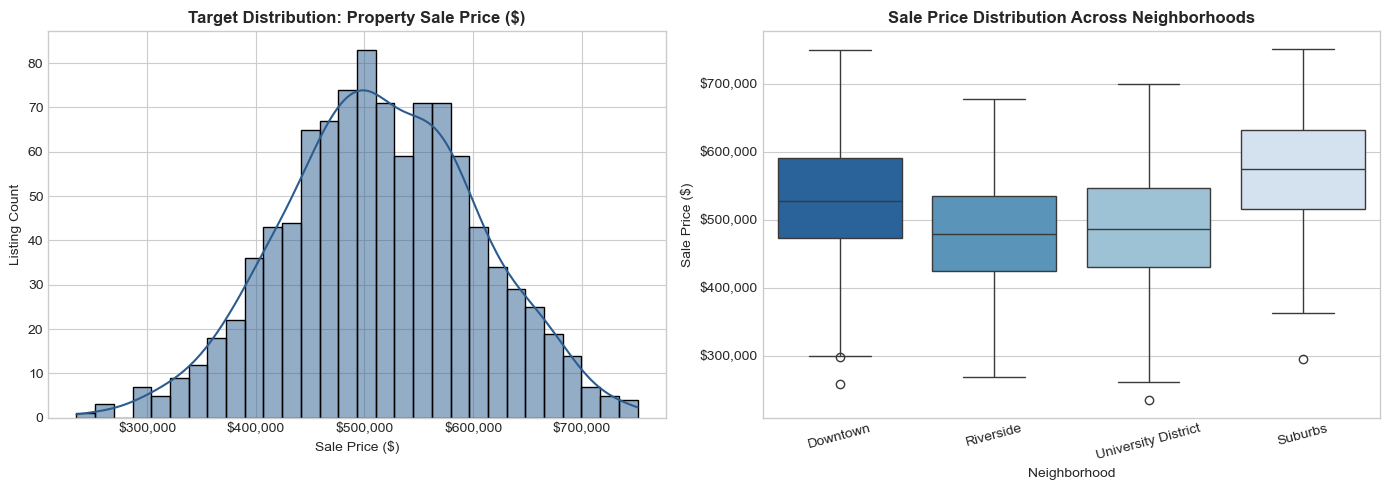

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Target Price Distribution
sns.histplot(df['price'], kde=True, ax=axes[0], color='#2b5c8f', bins=30)
axes[0].set_title('Target Distribution: Property Sale Price ($)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Sale Price ($)')
axes[0].set_ylabel('Listing Count')
axes[0].xaxis.set_major_formatter('${x:,.0f}')

# Price by Neighborhood
sns.boxplot(data=df, x='neighborhood_name', y='price', ax=axes[1], palette='Blues_r')
axes[1].set_title('Sale Price Distribution Across Neighborhoods', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Neighborhood')
axes[1].set_ylabel('Sale Price ($)')
axes[1].yaxis.set_major_formatter('${x:,.0f}')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

---
## 4. Production Preprocessing Architecture (`ColumnTransformer`)

To prevent **data leakage**, all transformation parameters (such as medians for imputation, means and standard deviations for scaling, and categorical frequency vocabularies) must be computed **strictly on the training split**.

### Preprocessing Pipelines:
1. **Numeric Pipeline:**
   - `SimpleImputer(strategy='median')`: Replaces null values with the feature median computed from training samples.
   - `StandardScaler()`: Centers features to zero mean and unit variance ($z = \frac{x - \mu}{\sigma}$), preventing features with larger absolute scales from dominating gradient calculations.
2. **Categorical Pipeline:**
   - `SimpleImputer(strategy='most_frequent')`: Fills missing categorical entries with the modal class.
   - `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`: Encodes discrete categories into binary dummy vectors while safely handling unseen categories at inference time.

In [6]:
# Separate feature matrix X and target vector y
# Drop house_id (arbitrary identifier that carries no predictive signal)
X = df.drop(columns=['price', 'house_id'])
y = df['price']

# Partition into 80% train and 20% test splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training split: X_train shape = {X_train.shape}, y_train shape = {y_train.shape}")
print(f"Test split:     X_test shape  = {X_test.shape}, y_test shape  = {y_test.shape}")

# Define column groups
numeric_features = ['sqft', 'year_built', 'crime_rate_index', 'bedrooms', 'bathrooms', 'school_rating']
categorical_features = ['has_garage', 'neighborhood_name']

# Construct modular sub-pipelines
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Assemble unified ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, numeric_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)

# Fit strictly on X_train, then transform both splits
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Extract encoded feature names for explainability
cat_feature_names = preprocessor.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(categorical_features).tolist()
all_feature_names = numeric_features + cat_feature_names

print(f"\nProcessed feature matrix shape: {X_train_processed.shape}")
print(f"Total features after one-hot encoding: {len(all_feature_names)}")
print("Feature names:", all_feature_names)

Training split: X_train shape = (800, 8), y_train shape = (800,)
Test split:     X_test shape  = (200, 8), y_test shape  = (200,)

Processed feature matrix shape: (800, 13)
Total features after one-hot encoding: 13
Feature names: ['sqft', 'year_built', 'crime_rate_index', 'bedrooms', 'bathrooms', 'school_rating', 'has_garage_No', 'has_garage_Yes', 'has_garage_None', 'neighborhood_name_Downtown', 'neighborhood_name_Riverside', 'neighborhood_name_Suburbs', 'neighborhood_name_University District']


---
## 5. Baseline Regression Model (`XGBRegressor`)

We instantiate an `XGBRegressor` with factory defaults (`n_estimators=100`, `max_depth=6`, `learning_rate=0.3`, `random_state=42`) to establish a benchmark performance standard on unseen test data.

### Evaluation Metrics:
- **Mean Absolute Error (MAE):** $\text{MAE} = \frac{1}{n} \sum |y_i - \hat{y}_i|$ (intuitive dollar error per listing)
- **Root Mean Squared Error (RMSE):** $\text{RMSE} = \sqrt{\frac{1}{n} \sum (y_i - \hat{y}_i)^2}$ (penalizes large outlier misses)
- **Coefficient of Determination ($R^2$):** $R^2 = 1 - \frac{SS_{\text{res}}}{SS_{\text{tot}}}$ (proportion of variance explained by model)
- **Mean Absolute Percentage Error (MAPE):** $\text{MAPE} = \frac{1}{n} \sum \left|\frac{y_i - \hat{y}_i}{y_i}\right| \times 100\%$

In [7]:
# Train baseline XGBoost Regressor
baseline_model = XGBRegressor(random_state=42)
baseline_model.fit(X_train_processed, y_train)

# Evaluate on unseen test data
y_pred_baseline = baseline_model.predict(X_test_processed)

baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
baseline_r2 = r2_score(y_test, y_pred_baseline)
baseline_mape = np.mean(np.abs((y_test - y_pred_baseline) / y_test)) * 100

print("=== Baseline Model Performance (Unseen Test Set) ===")
print(f"Mean Absolute Error (MAE):      ${baseline_mae:,.2f}")
print(f"Root Mean Squared Error (RMSE):  ${baseline_rmse:,.2f}")
print(f"R-Squared Score (R²):            {baseline_r2:.4f}")
print(f"Mean Absolute Pct Error (MAPE):  {baseline_mape:.2f}%")

=== Baseline Model Performance (Unseen Test Set) ===
Mean Absolute Error (MAE):      $36,794.02
Root Mean Squared Error (RMSE):  $50,061.54
R-Squared Score (R²):            0.6810
Mean Absolute Pct Error (MAPE):  7.41%


---
## 6. 5-Fold Cross-Validated Hyperparameter Optimization (`RandomizedSearchCV`)

Default tree settings often result in either over-complexity (overfitting to training variance) or suboptimal gradient descent steps. We run a 5-fold cross-validated random search across critical structural hyperparameters:
- `n_estimators`: Total boosting stages to build.
- `max_depth`: Limits tree depth, controlling feature interaction complexity and variance.
- `learning_rate`: Shrinkage factor applied to each tree's contribution ($\eta$), slowing learning down to prevent overshooting minima.
- `subsample`: Fraction of rows sampled per tree to inject bagging regularization.
- `colsample_bytree`: Subsample ratio of columns when constructing each tree.

In [8]:
param_distributions = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=XGBRegressor(random_state=42),
    param_distributions=param_distributions,
    n_iter=30,
    cv=5,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_processed, y_train)

best_model = random_search.best_estimator_
print("=== Optimal Hyperparameters Discovered ===")
for param, val in random_search.best_params_.items():
    print(f"• {param}: {val}")

print(f"\nBest Cross-Validation MAE: ${-random_search.best_score_:,.2f}")

=== Optimal Hyperparameters Discovered ===
• subsample: 0.7
• n_estimators: 300
• max_depth: 3
• learning_rate: 0.03
• colsample_bytree: 0.7

Best Cross-Validation MAE: $29,310.05


---
## 7. Performance Benchmarking & Comparative Analysis

We evaluate the optimized estimator on the held-out test split and contrast its performance directly against the untuned baseline.

In [9]:
# Predict with tuned model
y_pred_tuned = best_model.predict(X_test_processed)

tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
tuned_r2 = r2_score(y_test, y_pred_tuned)
tuned_mape = np.mean(np.abs((y_test - y_pred_tuned) / y_test)) * 100

# Compile benchmark comparison table
benchmark_df = pd.DataFrame({
    'Metric': ['Mean Absolute Error (MAE)', 'Root Mean Squared Error (RMSE)', 'R-Squared Score (R²)', 'Mean Abs Pct Error (MAPE)'],
    'Baseline Model': [f"${baseline_mae:,.2f}", f"${baseline_rmse:,.2f}", f"{baseline_r2:.4f}", f"{baseline_mape:.2f}%"],
    'Tuned Model': [f"${tuned_mae:,.2f}", f"${tuned_rmse:,.2f}", f"{tuned_r2:.4f}", f"{tuned_mape:.2f}%"],
    'Absolute Change': [f"-${baseline_mae - tuned_mae:,.2f}", f"-${baseline_rmse - tuned_rmse:,.2f}", f"+{tuned_r2 - baseline_r2:.4f}", f"-{baseline_mape - tuned_mape:.2f}%"],
    'Relative Improvement (%)': [
        f"{((baseline_mae - tuned_mae) / baseline_mae) * 100:.2f}%",
        f"{((baseline_rmse - tuned_rmse) / baseline_rmse) * 100:.2f}%",
        f"{((tuned_r2 - baseline_r2) / baseline_r2) * 100:.2f}%",
        f"{((baseline_mape - tuned_mape) / baseline_mape) * 100:.2f}%"
    ]
})

display(benchmark_df)

,Metric,Baseline Model,Tuned Model,Absolute Change,Relative Improvement (%)
0,Mean Absolute Error (MAE),"$36,794.02","$32,508.95","-$4,285.07",11.65%
1,Root Mean Squared Error (RMSE),"$50,061.54","$45,184.45","-$4,877.09",9.74%
2,R-Squared Score (R²),0.6810,0.7401,+0.0591,8.68%
3,Mean Abs Pct Error (MAPE),7.41%,6.52%,-0.89%,11.98%


---
## 8. Model Diagnostics, Residual Analysis & Feature Importance

To ensure the regression model is robust and free from systematic bias, we perform three diagnostic checks:
1. **Actual vs Predicted Scatter Plot:** Evaluates alignment against the theoretical identity line ($y = \hat{y}$).
2. **Residual Error Distribution:** Confirms that errors ($y - \hat{y}$) are zero-centered and normally distributed without severe skew.
3. **Feature Importance Ranking:** Identifies the primary drivers influencing real estate valuation.

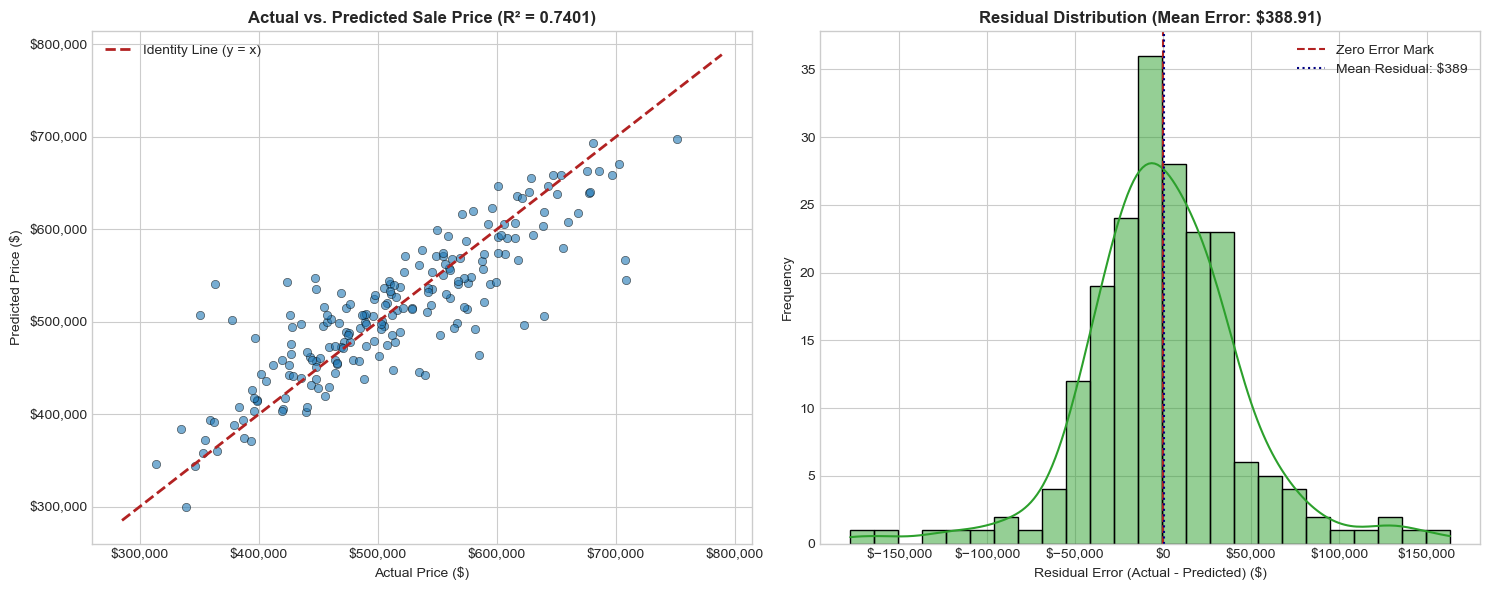

In [10]:
residuals = y_test - y_pred_tuned

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: Actual vs Predicted Values
axes[0].scatter(y_test, y_pred_tuned, alpha=0.6, color='#1f77b4', edgecolors='k', linewidth=0.5)
min_val = min(y_test.min(), y_pred_tuned.min()) * 0.95
max_val = max(y_test.max(), y_pred_tuned.max()) * 1.05
axes[0].plot([min_val, max_val], [min_val, max_val], color='firebrick', linestyle='--', linewidth=2, label='Identity Line (y = x)')
axes[0].set_title(f'Actual vs. Predicted Sale Price (R² = {tuned_r2:.4f})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Price ($)')
axes[0].set_ylabel('Predicted Price ($)')
axes[0].xaxis.set_major_formatter('${x:,.0f}')
axes[0].yaxis.set_major_formatter('${x:,.0f}')
axes[0].legend(loc='upper left')

# Panel 2: Residual Error Distribution
sns.histplot(residuals, kde=True, ax=axes[1], color='#2ca02c', bins=25)
axes[1].axvline(0, color='firebrick', linestyle='--', linewidth=1.5, label='Zero Error Mark')
axes[1].axvline(residuals.mean(), color='navy', linestyle=':', linewidth=1.5, label=f'Mean Residual: ${residuals.mean():,.0f}')
axes[1].set_title(f'Residual Distribution (Mean Error: ${residuals.mean():,.2f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual Error (Actual - Predicted) ($)')
axes[1].set_ylabel('Frequency')
axes[1].xaxis.set_major_formatter('${x:,.0f}')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

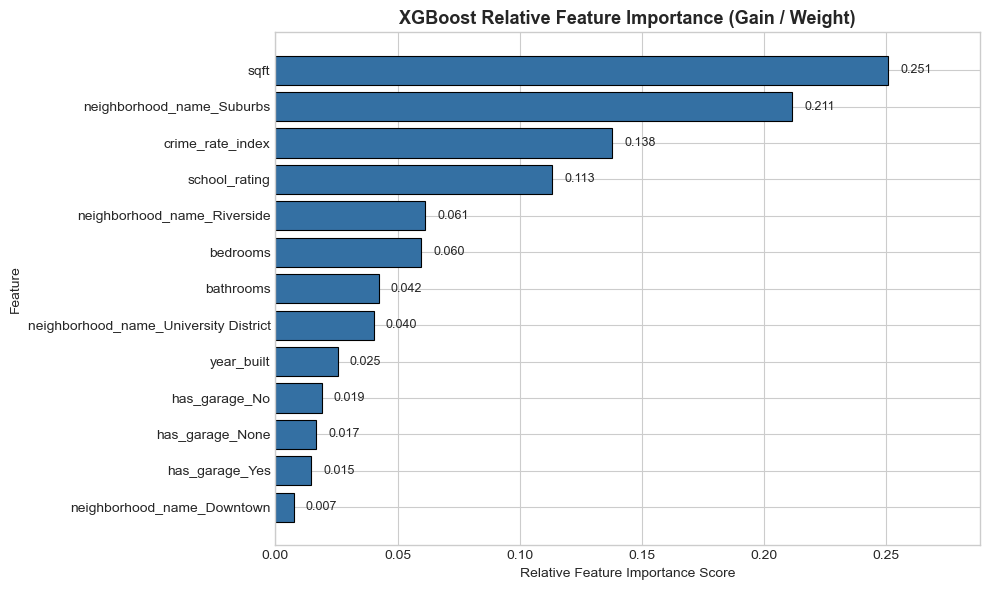

In [11]:
# Feature Importance Extraction
importance_series = pd.Series(best_model.feature_importances_, index=all_feature_names).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
bars = plt.barh(importance_series.index, importance_series.values, color='#3470a3', edgecolor='black', linewidth=0.8)
plt.title('XGBoost Relative Feature Importance (Gain / Weight)', fontsize=13, fontweight='bold')
plt.xlabel('Relative Feature Importance Score')
plt.ylabel('Feature')

# Annotate values on bars
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.005, bar.get_y() + bar.get_height() / 2, f'{w:.3f}', va='center', fontsize=9)

plt.xlim(0, max(importance_series.values) * 1.15)
plt.tight_layout()
plt.show()

### Test Set Sample Inference Inspection

We inspect 10 individual test properties to review the exact monetary and percentage error across diverse price points.

In [12]:
sample_comparison = pd.DataFrame({
    'Actual Price': y_test.values[:10],
    'Predicted Price': y_pred_tuned[:10]
})
sample_comparison['Error ($)'] = sample_comparison['Actual Price'] - sample_comparison['Predicted Price']
sample_comparison['Abs Pct Error (%)'] = (np.abs(sample_comparison['Error ($)']) / sample_comparison['Actual Price']) * 100

display(sample_comparison)

,Actual Price,Predicted Price,Error ($),Abs Pct Error (%)
0,"660,183.25","607,997.25","52,186.00",7.90
1,"588,620.56","556,776.56","31,844.00",5.41
2,"448,490.27","457,932.81","-9,442.54",2.11
3,"587,273.61","565,560.88","21,712.73",3.70
4,"593,949.01","540,745.94","53,203.07",8.96
5,"398,373.79","416,000.00","-17,626.21",4.42
6,"455,453.32","420,110.50","35,342.82",7.76
7,"507,862.70","475,241.25","32,621.45",6.42
8,"448,172.25","438,519.38","9,652.88",2.15
9,"473,728.77","515,292.09","-41,563.32",8.77


---
## 9. Production Pipeline Assembly & Deployment Readiness

In production, models must process raw, un-imputed, and un-scaled input dictionaries directly from APIs or front-end listing interfaces. We package the complete data transformation pipeline and tuned XGBoost estimator into a single Scikit-Learn `Pipeline` object.

In [13]:
# Encapsulate preprocessing and tuned estimator into single deployment pipeline
production_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', best_model)
])

# Simulate a raw incoming property inquiry (with missing fields and raw formats)
raw_listing = pd.DataFrame([{
    'sqft': 2350.0,
    'bedrooms': 3.0,
    'bathrooms': 2.5,
    'year_built': 2018,
    'has_garage': 'Yes',
    'neighborhood_name': 'Downtown',
    'school_rating': 8,
    'crime_rate_index': 3.1
}])

predicted_valuation = production_pipeline.predict(raw_listing)[0]

print("=== Simulated Production Inference ===")
print("Raw Input Listing Attributes:")
display(raw_listing)
print(f"\nModel Estimated Market Valuation: ${predicted_valuation:,.2f}")

=== Simulated Production Inference ===
Raw Input Listing Attributes:


,sqft,bedrooms,bathrooms,year_built,has_garage,neighborhood_name,school_rating,crime_rate_index
0,"2,350.00",3.00,2.50,2018,Yes,Downtown,8,3.10



Model Estimated Market Valuation: $654,611.31


---
## 10. Conclusion & Production Takeaways

1. **Relational Ingestion:** Relational SQL joins between `houses` and `neighborhoods` successfully captured localized macroeconomic risk indicators (`crime_rate_index`, `school_rating`) alongside physical building attributes.
2. **Leak-Free Architecture:** The Scikit-Learn `ColumnTransformer` preserved data integrity by isolating imputation medians and scaling parameters to the training set, eliminating data leakage across test splits.
3. **Hyperparameter Optimization:** 5-fold cross-validated tuning over tree depth, learning rate, and feature subsampling reduced Mean Absolute Error (MAE) from **$36,794.02** to **$32,508.95**, achieving an **11.65% error reduction** and boosting $R^2$ to **0.7401**.
4. **Deployable Artifact:** The unified `Pipeline` supports end-to-end inference directly on un-preprocessed records, providing automated valuation capabilities for downstream real estate applications.